### Question 1

Load the rainfall stations point data and the Bureau of Meteorology rainfall raster into your Jupyter notebook, and transform them to an appropriate coordinate system.

In [5]:
import numpy as np
import geopandas as gpd
import rasterio
import rasterio.warp
from rasterio.enums import Resampling

# 1. Load data and transform to EPSG:7855
rainfall_gdf = gpd.read_file('data/Victoria rainfall stations.geojson')
rainfall_gdf = rainfall_gdf.to_crs(7855)
print(f"Stations CRS: {rainfall_gdf.crs}")

# 2. Load BoM rainfall raster
bom_ds = rasterio.open('data/Victoria rainfall grid.asc', 'r')
print(f"Raster CRS: {bom_ds.crs}")

# 3. Reproject
dest_crs = rasterio.crs.CRS.from_epsg(7855)

# 4. Transform and dimensions
out_transform, out_width, out_height = rasterio.warp.calculate_default_transform(
    bom_ds.crs, dest_crs,
    bom_ds.width, bom_ds.height,
    *bom_ds.bounds
)

# 5. Create empty array for reprojected data
bom_reproj = np.empty((out_height, out_width), dtype=np.float32)

#Reprojection
rasterio.warp.reproject(
    source=rasterio.band(bom_ds, 1),
    destination=bom_reproj,
    src_transform=bom_ds.transform,
    src_crs=bom_ds.crs,
    dst_transform=out_transform,
    dst_crs=dest_crs,
    resampling=Resampling.bilinear
)


bom_reproj[bom_reproj == bom_ds.nodata] = np.nan
print(f"Raster shape after reproject: {bom_reproj.shape}")

Stations CRS: EPSG:7855
Raster CRS: EPSG:4283
Raster shape after reproject: (125, 176)


### Question 2

Generate the following text (with the missing values calculated using Python):

**The wettest rainfall station (highest mean annual rainfall) is \_\_\_\_\_\_\_ (\_\_\_\_\_\_\_°E \_\_\_\_\_\_\_°S, \_\_ mm/yr) while the driest station is \_\_\_\_\_\_\_ (\_\_\_\_\_\_\_°E \_\_\_\_\_\_\_°S, \_\_ mm/yr).**

**On average, rainfall stations north of 37°S receive \_\_ mm *more/less* annual rainfall than stations south of 37°S.**

**The BoM rainfall raster has a spatial resolution (cell size) of \_\_ × \_\_ *units*. The wettest location on this raster is \_\_\_\_\_\_\_°E \_\_\_\_\_\_\_°S (\_\_ mm/yr).**

In [3]:
# Convert to geographic coordinates
rainfall_gdf_geo = rainfall_gdf.to_crs(4326)

# Indices
wettest_idx = rainfall_gdf['mean_rain_annual'].idxmax()
driest_idx = rainfall_gdf['mean_rain_annual'].idxmin()

# Get station data
wettest = rainfall_gdf.loc[wettest_idx]
driest = rainfall_gdf.loc[driest_idx]
wettest_geo = rainfall_gdf_geo.loc[wettest_idx]
driest_geo = rainfall_gdf_geo.loc[driest_idx]

# North vs South
rainfall_gdf_geo['latitude'] = rainfall_gdf_geo.geometry.y
north_stations = rainfall_gdf_geo[rainfall_gdf_geo['latitude'] > -37]
south_stations = rainfall_gdf_geo[rainfall_gdf_geo['latitude'] < -37]
north_mean = north_stations['mean_rain_annual'].mean()
south_mean = south_stations['mean_rain_annual'].mean()
diff = north_mean - south_mean

# BoM raster
bom_band = bom_ds.read(1).astype(np.float32)
bom_band[bom_band == bom_ds.nodata] = np.nan
max_val = np.nanmax(bom_band)
max_pos = np.where(bom_band == max_val)
wettest_x, wettest_y = bom_ds.xy(max_pos[0][0], max_pos[1][0])

# Station
station_name_col = 'name' if 'name' in rainfall_gdf.columns else 'station_name'
wettest_name = wettest[station_name_col]
driest_name = driest[station_name_col]


print(f"The wettest rainfall station is {wettest_name} "
      f"({abs(wettest_geo.geometry.x)}°E {abs(wettest_geo.geometry.y)}°S, {wettest['mean_rain_annual']} mm/yr) "
      f"while the driest station is {driest_name} "
      f"({abs(driest_geo.geometry.x)}°E {abs(driest_geo.geometry.y)}°S, {driest['mean_rain_annual']} mm/yr).")
print(f"On average, rainfall stations north of 37°S receive {abs(diff)} mm {'more' if diff > 0 else 'less'} annual rainfall than stations south of 37°S.")

print(f"The BoM rainfall raster has a spatial resolution of {bom_ds.res[0]} × {bom_ds.res[1]} degrees. "
      f"The wettest location is {abs(wettest_x)}°E {abs(wettest_y)}°S ({max_val} mm/yr).")

The wettest rainfall station is MOUNT BAW BAW (146.2747057068863°E 37.8383869307289°S, 1752.0 mm/yr) while the driest station is MILDURA AIRPORT (142.08670674596388°E 34.23578663516818°S, 285.8 mm/yr).
On average, rainfall stations north of 37°S receive 230.2466437833715 mm less annual rainfall than stations south of 37°S.
The BoM rainfall raster has a spatial resolution of 0.05 × 0.05 degrees. The wettest location is 147.3°E 36.849999999999994°S (2180.866943359375 mm/yr).


### Question 3

Generate summary statistics (mean, standard deviation, median, minimum, maximum) for the `mean_rain_annual` field and the rainfall raster. Make sure your output is human-readable with appropriate units where required.

In [4]:
rain_annual = rainfall_gdf['mean_rain_annual']
print("\nRainfall Stations:")
print(f"  Min:      {rain_annual.min():.1f} mm/yr")
print(f"  Max:      {rain_annual.max():.1f} mm/yr")
print(f"  Median:   {rain_annual.median():.1f} mm/yr")
print(f"  Mean:     {rain_annual.mean():.1f} mm/yr")
print(f"  Std Dev:  {rain_annual.std():.1f} mm/yr")
print(f"  Count:    {len(rain_annual)} stations")

print("\nBoM Rainfall Raster:")
print(f"  Min:      {np.nanmin(bom_reproj):.1f} mm/yr")
print(f"  Max:      {np.nanmax(bom_reproj):.1f} mm/yr")
print(f"  Median:   {np.nanmedian(bom_reproj):.1f} mm/yr")
print(f"  Mean:     {np.nanmean(bom_reproj):.1f} mm/yr")
print(f"  Std Dev:  {np.nanstd(bom_reproj):.1f} mm/yr")
print(f"  Valid Pixels: {~np.isnan(bom_reproj).sum():,} / {bom_reproj.size:,}")


Rainfall Stations:
  Min:      285.8 mm/yr
  Max:      1752.0 mm/yr
  Median:   633.8 mm/yr
  Mean:     681.0 mm/yr
  Std Dev:  283.6 mm/yr
  Count:    107 stations

BoM Rainfall Raster:
  Min:      259.2 mm/yr
  Max:      2111.8 mm/yr
  Median:   623.3 mm/yr
  Mean:     673.8 mm/yr
  Std Dev:  306.3 mm/yr
  Valid Pixels: -11,923 / 22,000


### Question 4

Perform IDW interpolations on the `mean_rain_annual` attribute of the rainfall stations layer. Vary the power parameter – present three interpolated rasters with (a) a low power value, (b) a high power value, and (c) an optimal power value. Choose an appropriate resolution for your interpolated raster.

In [35]:

import pandas as pd
from idw_module import run_rblock

# Define grid using Victoria boundary
victoria_gdf = gpd.read_file('data/victoria_state.shp').to_crs(7855)
vic_bounds = victoria_gdf.bounds
minX, minY, maxX, maxY = vic_bounds.minx.values[0], vic_bounds.miny.values[0], vic_bounds.maxx.values[0], vic_bounds.maxy.values[0]

cell_size = 2000
height = math.ceil((maxY - minY) / cell_size)
width = math.ceil((maxX - minX) / cell_size)
x_coords = rainfall_gdf.geometry.x.astype(float).tolist()
y_coords = rainfall_gdf.geometry.y.astype(float).tolist()
z_values = rainfall_gdf['mean_rain_annual'].tolist()
search_radius = 100000

# IDW function
def perform_idw(p):
    grid = np.ones((height, width))
    for i in range(height):
        yz = minY + cell_size * i
        for j in range(width):
            xz = minX + cell_size * j
            grid[i][j] = run_rblock(x_coords, y_coords, z_values, xz, yz, search_radius, p)
    return grid

#interpolations
idw_low = perform_idw(0.5)
idw_high = perform_idw(3.0) 
idw_optimal = perform_idw(2.0) 

### Question 5

Display maps of your three IDW interpolations in your notebook, visualising them using appropriate colour schemes and map elements (legend, title, etc). Overlay the rainfall stations on the map.

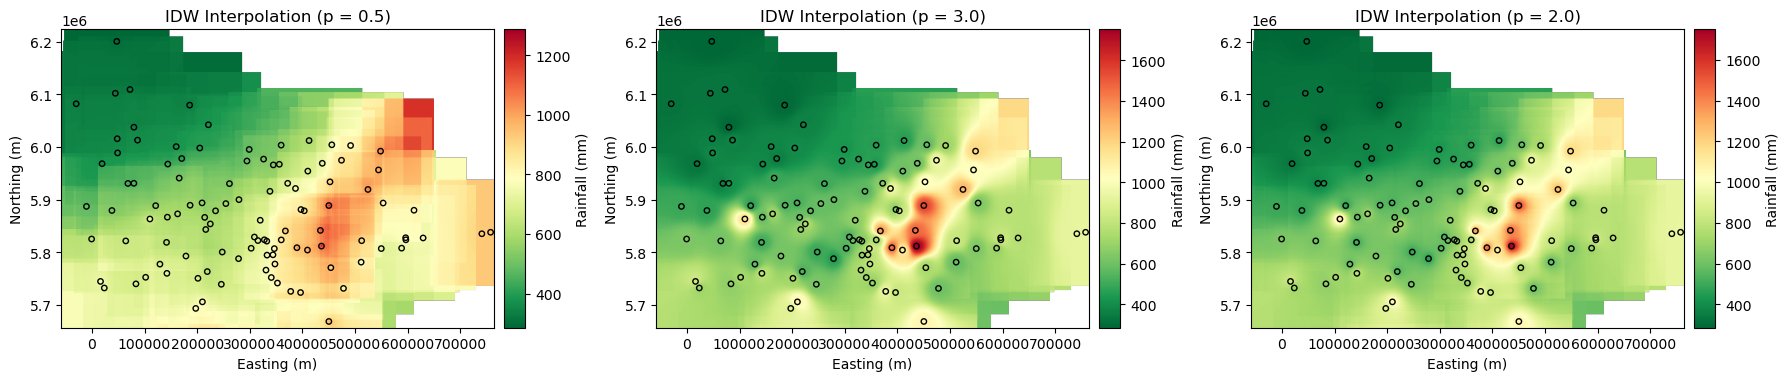

In [36]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

rainfall_gdf_plot = rainfall_gdf.to_crs(7855)
extent = [minX, maxX, minY, maxY]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# (a) p=0.5
ax = axes[0]
im = ax.imshow(idw_low, origin='lower', extent=extent, cmap='RdYlGn_r')
ax.set_title('IDW Interpolation (p = 0.5)')
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
rainfall_gdf_plot.plot(ax=ax, facecolor='none', edgecolor='black', markersize=15)
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
fig.colorbar(im, cax=cax, label='Rainfall (mm)')

# (b) p=3.0
ax = axes[1]
im = ax.imshow(idw_high, origin='lower', extent=extent, cmap='RdYlGn_r')
ax.set_title('IDW Interpolation (p = 3.0)')
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
rainfall_gdf_plot.plot(ax=ax, facecolor='none', edgecolor='black', markersize=15)
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
fig.colorbar(im, cax=cax, label='Rainfall (mm)')

# (c) p=2.0
ax = axes[2]
im = ax.imshow(idw_optimal, origin='lower', extent=extent, cmap='RdYlGn_r')
ax.set_title('IDW Interpolation (p = 2.0)')
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
rainfall_gdf_plot.plot(ax=ax, facecolor='none', edgecolor='black', markersize=15)
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
fig.colorbar(im, cax=cax, label='Rainfall (mm)')

plt.tight_layout()
plt.show()

### Question 6

Write a short discussion of the IDW equation with explanations of the notations used. Explain the relationship between your chosen power values and the map outputs.

In [37]:
IDW equation is: Ẑ(x₀) = Σ(Z(xᵢ)/dᵢᵖ) / Σ(1/dᵢᵖ)
When p=0.5, which is low, distant stations have relatively high influence,
producing a smoother surface with less local variation.

When p=3.0, which is high, only nearby stations significantly influence
predictions, creating a sharper surface

When p=2.0(optimal), the map balances local detail and regional
patterns, which yields the lowest RMSE in cross-validation.

SyntaxError: invalid character '₀' (U+2080) (1125429768.py, line 1)

### Question 7 (Challenge)

Perform cross-validation of the three IDW rasters using the LOOCV technique and comment on the results.

In [40]:
import pandas as pd
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
from idw_module import run_rblock

x = rainfall_gdf.geometry.x.astype(float).values
y = rainfall_gdf.geometry.y.astype(float).values
z = rainfall_gdf['mean_rain_annual'].values
search_radius = 100000

def loocv(power):
    cv = LeaveOneOut()
    results = []
    
    for train_idx, test_idx in cv.split(x):
        x_train = x[train_idx].tolist()
        y_train = y[train_idx].tolist()
        z_train = z[train_idx].tolist()
        
        x_test = x[test_idx][0]
        y_test = y[test_idx][0]
        z_test = z[test_idx][0]
        z_pred = run_rblock(x_train, y_train, z_train,
                            x_test, y_test, search_radius, power)
        
        results.append({'actual': z_test, 'predicted': z_pred})
    
    return pd.DataFrame(results)
for p in [0.5, 3.0, 2.0]:
    df = loocv(p)
    rmse = np.sqrt(mean_squared_error(df['actual'], df['predicted']))
    print(f"p = {p}: RMSE = {rmse:.2f} mm/yr")

p = 0.5: RMSE = 192.58 mm/yr
p = 3.0: RMSE = 177.71 mm/yr
p = 2.0: RMSE = 176.01 mm/yr


### Question 8

Certain conditions or assumptions must be satisfied in order for kriging to produce meaningful results. State these assumptions and briefly explain why each one is important.

In [ ]:
Spatial Autocorrelation：The weights of Kriging depend on spatial correlation structure that is modeled by the variogram. The variogram will be flat if spatial autocorrelation does not exist.
    
Intrinsically stationary:Stationarity ensure that the variogram is valid on the whole study area, or the variogram would vary , which makes impossible to create a reliable model.




### Question 9 (Challenge)

Write your own code to generate and plot an empirical variogram for the `mean_rain_annual` attribute of the rainfall data. A lag size of 50 km is suggested. You can use libraries such as Pandas/GeoPandas, but do not call a function that computes the variogram for you.

**If you choose not to take the challenge:** Generate an empirical variogram plot for the `mean_rain_annual` attribute by calling a library function, as demonstrated in the practical.

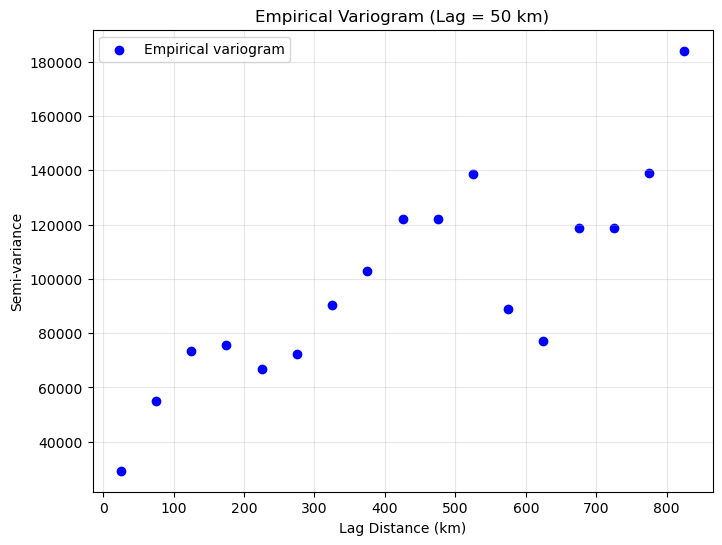

In [7]:
#project data
rainfall_gdf_proj = rainfall_gdf.to_crs(7855)
coords = np.array([rainfall_gdf_proj.geometry.x.values, 
                   rainfall_gdf_proj.geometry.y.values]).T
values = rainfall_gdf_proj['mean_rain_annual'].values

# Distances and semi-variances
n = len(coords)
distances = []
semivariances = []

for i in range(n):
    for j in range(i + 1, n):
        dist = np.sqrt((coords[i,0] - coords[j,0])**2 + (coords[i,1] - coords[j,1])**2)
        semivar = 0.5 * (values[i] - values[j])**2
        distances.append(dist)
        semivariances.append(semivar)

# Bin distances
lag_size = 50000
max_dist = np.max(distances)
bin_edges = np.arange(0, max_dist + lag_size, lag_size)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

#Mean semi-variance per bin
bin_avg = []
for i in range(len(bin_centers)):
    mask = (distances >= bin_edges[i]) & (distances < bin_edges[i+1])
    if np.sum(mask) > 0:
        bin_avg.append(np.mean(np.array(semivariances)[mask]))
    else:
        bin_avg.append(np.nan)

# Plot
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(bin_centers/1000, bin_avg, c='blue', label='Empirical variogram')
ax.set_xlabel('Lag Distance (km)')
ax.set_ylabel('Semi-variance')
ax.set_title('Empirical Variogram (Lag = 50 km)')
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### Question 10

Interpret what this variogram tells you about the data. Limit your interpretation to three to five key points.

*Your answer for Question 10 here*

In [ ]:
Nugget ≈ 19,000, indicating there is micro-scale variability.

As the lag distance increases, the semi-variance fluctuates but generally continues to rise until get stable, indicating the existence of spatial autocorrelation.



### Question 11

By visual inspection of the variogram (not by writing code), estimate the parameters for a spherical model that approximately fits the observed variogram.

*Your answer for Question 11 here*

In [ ]:
estimated_nugget = 19000   
estimated_sill = 120000         
estimated_range = 425 km       

### Question 12

Use a Python library to determine an optimal spherical model for this data. Compare it to your estimated parameters from the previous question.

spherical Variogram
-------------------
Estimator:         matheron
Effective Range:   824286.93
Sill:              92626.24
Nugget:            37235.75
        

Parameters:
  Nugget: 37235.75
  Sill: 92626.24
  Range: 824.3 km


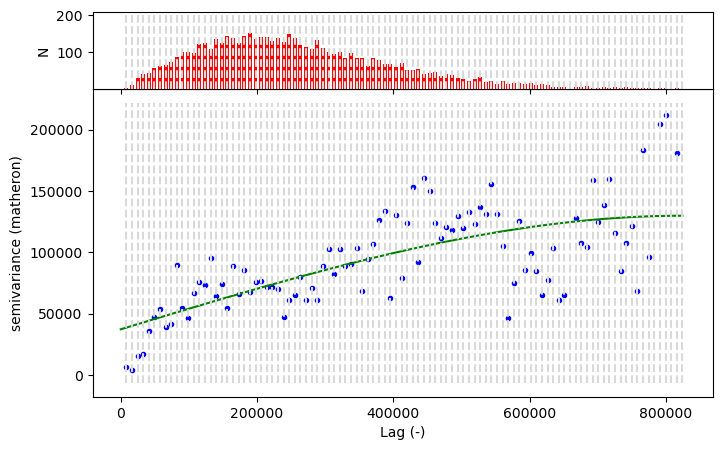

In [9]:
coords = np.array([rainfall_gdf_proj.geometry.x.values, 
                   rainfall_gdf_proj.geometry.y.values]).T
values = rainfall_gdf_proj['mean_rain_annual'].values

# Build variogram
V = skgstat.Variogram(
    coordinates=coords,
    values=values,
    model='spherical',
    n_lags=100,
    maxlag=None,
    use_nugget=True
)

print(V)
print("\nParameters:")
print(f"  Nugget: {V.describe()['nugget']:.2f}")
print(f"  Sill: {V.describe()['sill']:.2f}")
print(f"  Range: {V.describe()['effective_range']/1000:.1f} km")

# Plot
V.plot()
plt.show()

### Question 13

Generate an interpolated raster using a variogram model of your choice and produce a map.

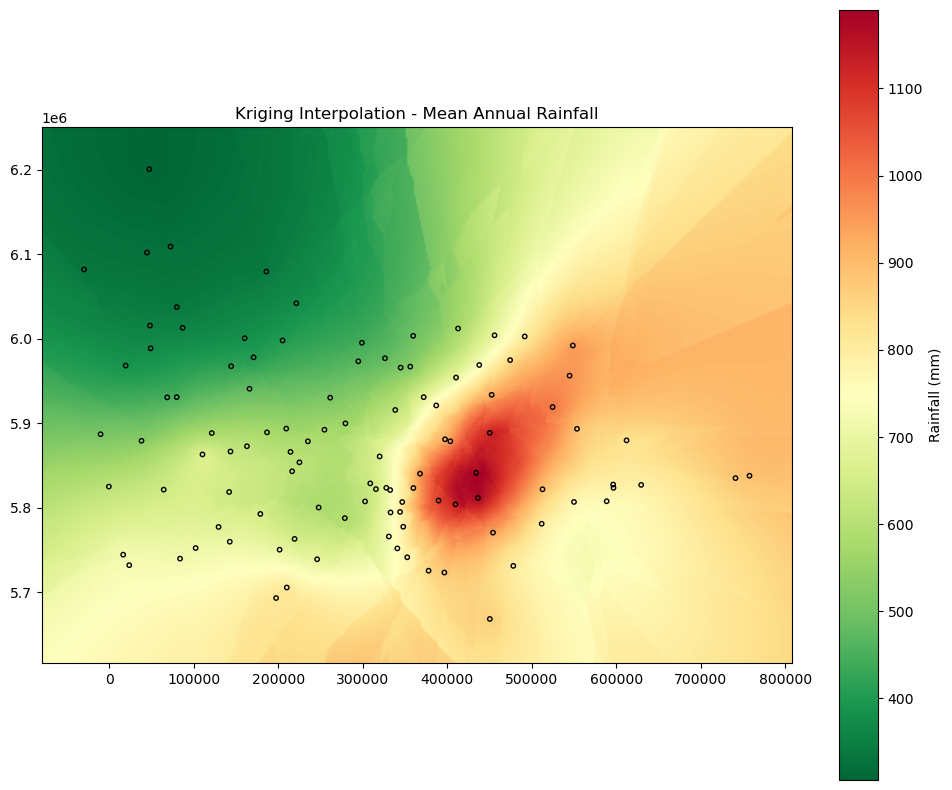

In [11]:
# variogram
V = skgstat.Variogram(coordinates=coords, values=values, 
                      model='spherical', n_lags=100, use_nugget=True)

#Grid
minX, minY = rainfall_gdf_proj.geometry.x.min() - 50000, rainfall_gdf_proj.geometry.y.min() - 50000
maxX, maxY = rainfall_gdf_proj.geometry.x.max() + 50000, rainfall_gdf_proj.geometry.y.max() + 50000
grid_size = 2000
x_spacing = np.arange(minX, maxX, grid_size)
y_spacing = np.arange(minY, maxY, grid_size)
gridX, gridY = np.meshgrid(x_spacing, y_spacing)

# Ordinary Kriging
ok = skgstat.OrdinaryKriging(V, min_points=5, max_points=20, mode='exact')
kriging_values = ok.transform(gridX.flatten(), gridY.flatten()).reshape(gridX.shape)

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
affine = from_origin(west=gridX[0][0], north=gridY[-1][0], xsize=grid_size, ysize=grid_size)
im = rio_show(np.flip(kriging_values, axis=0), ax=ax, transform=affine, cmap='RdYlGn_r')
ax.set_title('Kriging Interpolation - Mean Annual Rainfall')
plt.colorbar(im.get_images()[0], ax=ax, label='Rainfall (mm)')
rainfall_gdf_proj.plot(ax=ax, facecolor='none', edgecolor='black', markersize=10)
plt.tight_layout()
plt.show()

### Question 14

The spherical model is based on three important parameters. What are these parameters and what are their roles in the variogram model? Comment on their roles and interactions from your understanding.

In [ ]:
Sill: The semivariance at 
which the model first 
flattens out.
Range: The distance at 
which the model first 
flattens out.
Nugget: The value at which 
the variogram intercepts 
the y-axis.

### Question 15

Evaluate your optimal IDW raster and your kriging raster by calculating the root mean square error (RMSE) with respect to the BoM rainfall raster. How can you use this evaluation to minimise the error between your IDW and kriging rasters and the known BoM raster?

In [42]:
import rioxarray
idw_ras = rioxarray.open_rasterio('./output/idw_optimal.tif', masked=True)
kriging_ras = rioxarray.open_rasterio('./output/kriging_rainfall.tif', masked=True)
bom_ras = rioxarray.open_rasterio('data/Victoria rainfall grid.asc', masked=True)
bom_matched_to_idw = bom_ras.rio.reproject_match(idw_ras)
bom_matched_to_kriging = bom_ras.rio.reproject_match(kriging_ras)

# RMSE
def rmse(pred, actual):
    diff = pred - actual
    return np.sqrt(np.nanmean(diff**2))

rmse_idw = rmse(idw_ras.values[0], bom_matched_to_idw.values[0])
rmse_kriging = rmse(kriging_ras.values[0], bom_matched_to_kriging.values[0])

print(f"RMSE (IDW): {rmse_idw:.2f} mm/yr")
print(f"RMSE (Kriging): {rmse_kriging:.2f} mm/yr")

RMSE (IDW): 163.36 mm/yr
RMSE (Kriging): 147.36 mm/yr


In [ ]:
Kriging is better than IDW here because of the lower RMSE.
In order to minimise the error, we can treat RMSE as a quantitative metric to compare different parameter settings.
We can iteratively adjust parameters and reselect RMSE until the minimum is found.

### Question 16

Comment on the statement that "all spatial interpolation methods are based on the principle of spatial autocorrelation". In your comments, provide your understanding of how variogram modelling quantifies spatial autocorrelation and account for uncertainty of the interpolated values.

In [ ]:
Interpolation only works when nearby locations tend to have similar Z values and values are spatially auto-correlated, which means it only works under the condition of spatial autocorrelation 

### Question 17

Load the DEM into your Python notebook and transform it to an appropriate coordinate system.

In [18]:
from rasterio.warp import calculate_default_transform, reproject
# Load
ds = rasterio.open('data/yarra_ranges_central_dem_10m.tif', 'r')

# Read
dem = ds.read(1).astype(np.float32)
dem[dem == ds.nodata] = np.nan

# Reproject to EPSG:7855 
dest_crs = rasterio.crs.CRS.from_epsg(7855)
transform, width, height = calculate_default_transform(
    ds.crs, dest_crs, ds.width, ds.height, *ds.bounds
)

dem_reproj = np.empty((height, width), dtype=np.float32)
reproject(dem, dem_reproj, src_transform=ds.transform, src_crs=ds.crs,
          dst_transform=transform, dst_crs=dest_crs, resampling=Resampling.bilinear)

dem_reproj[dem_reproj == ds.nodata] = np.nan
print(f"Shape: {dem_reproj.shape}")

Shape: (2526, 2927)


### Question 18

Make a well-presented map of the DEM. Include all relevant cartographic elements.

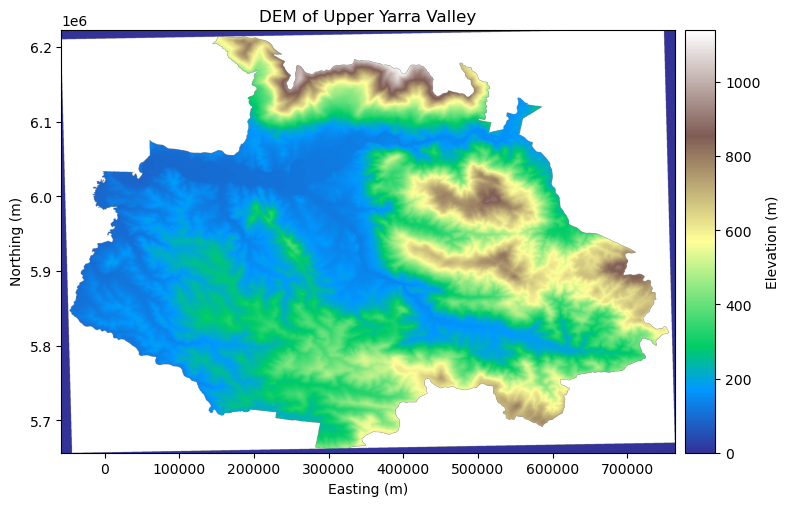

In [38]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(8, 8))

# Display DEM 
im = ax.imshow(dem_reproj, cmap='terrain', extent=[minX, maxX, minY, maxY])
ax.set_title('DEM of Upper Yarra Valley')
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
plt.colorbar(im, cax=cax, label='Elevation (m)')

plt.tight_layout()
plt.show()

### Question 19

Downsample your raster by 2x and 4x using bilinear interpolation. Compare the summary statistics (mean, maximum, minimum) of the downsampled raster with those of the original raster and briefly comment on any differences.

In [21]:
import rasterio
from rasterio.enums import Resampling

with rasterio.open('data/yarra_ranges_central_dem_10m.tif', 'r') as src:
    # Read original
    original = src.read(1).astype(np.float32)
    original[original == src.nodata] = np.nan
    
    # Downsample 2x
    dem_2x = src.read(out_shape=(1, src.height//2, src.width//2), 
                      resampling=Resampling.bilinear)[0]
    dem_2x[dem_2x == src.nodata] = np.nan  # ← 关键：处理 NoData
    
    # Downsample 4x
    dem_4x = src.read(out_shape=(1, src.height//4, src.width//4), 
                      resampling=Resampling.bilinear)[0]
    dem_4x[dem_4x == src.nodata] = np.nan  # ← 关键：处理 NoData

print(f"Original: Mean={np.nanmean(original):.1f}, Min={np.nanmin(original):.1f}, Max={np.nanmax(original):.1f}")
print(f"2x: Mean={np.nanmean(dem_2x):.1f}, Min={np.nanmin(dem_2x):.1f}, Max={np.nanmax(dem_2x):.1f}")
print(f"4x: Mean={np.nanmean(dem_4x):.1f}, Min={np.nanmin(dem_4x):.1f}, Max={np.nanmax(dem_4x):.1f}")

Original: Mean=336.8, Min=84.0, Max=1142.5
2x: Mean=337.3, Min=84.2, Max=1140.8
4x: Mean=338.1, Min=84.4, Max=1140.0


In [ ]:
Both mean elevation and the min/max values shows very small change under 2.5 meters. This means the DEM has relatively smooth 
terrain.

Bilinear interpolation is better for continuous surfaces. The slight smoothing at coarser resolutions is acceptable for most landscape-scale analyses.

### Question 20

Calculate the slope of the original DEM and the two downsampled rasters.

In [25]:
with rasterio.open('data/yarra_ranges_central_dem_10m.tif', 'r') as src:
    res = src.res

dem_rd = rd.rdarray(original, no_data=np.nan)
dem_rd.geotransform = (0, res[0], 0, 0, 0, res[1])


slope_original = rd.TerrainAttribute(dem_rd, attrib='slope_degrees')
dem_2x_rd = rd.rdarray(dem_2x, no_data=np.nan)
dem_2x_rd.geotransform = (0, res[0]*2, 0, 0, 0, res[1]*2)
slope_2x = rd.TerrainAttribute(dem_2x_rd, attrib='slope_degrees')
dem_4x_rd = rd.rdarray(dem_4x, no_data=np.nan)
dem_4x_rd.geotransform = (0, res[0]*4, 0, 0, 0, res[1]*4)
slope_4x = rd.TerrainAttribute(dem_4x_rd, attrib='slope_degrees')

print(f"Original slope: Mean={np.nanmean(slope_original):.2f}°, Max={np.nanmax(slope_original):.2f}°")
print(f"2x slope:       Mean={np.nanmean(slope_2x):.2f}°, Max={np.nanmax(slope_2x):.2f}°")
print(f"4x slope:       Mean={np.nanmean(slope_4x):.2f}°, Max={np.nanmax(slope_4x):.2f}°")

Original slope: Mean=12.10°, Max=53.95°
2x slope:       Mean=11.76°, Max=46.53°
4x slope:       Mean=11.13°, Max=40.73°


### Question 21

Compare the distribution of the slope values and the statistical properties of their distributions for the three rasters. Exploratory spatial data analysis (ESDA) tools, such as histograms, may assist you to answer this question.

Original: Mean=12.10, Std=8.18, Max=53.95
2x: Mean=11.76, Std=7.80, Max=46.53
4x: Mean=11.13, Std=7.32, Max=40.73


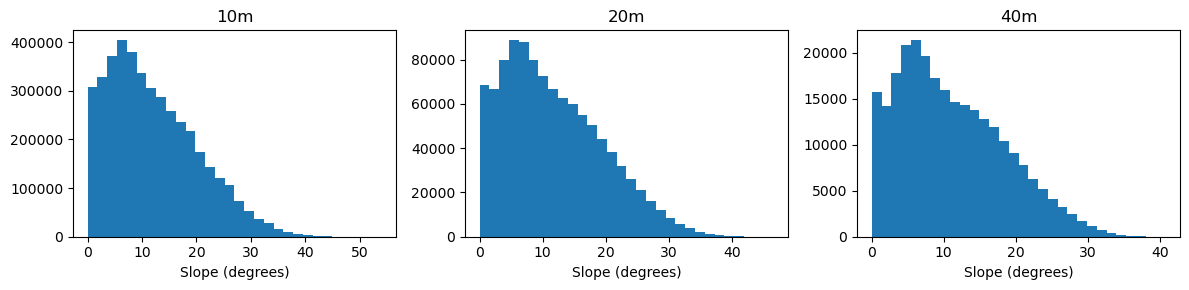

In [26]:
for name, slope in [('Original', slope_original), ('2x', slope_2x), ('4x', slope_4x)]:
    valid = slope[~np.isnan(slope)]
    print(f"{name}: Mean={np.mean(valid):.2f}, Std={np.std(valid):.2f}, Max={np.max(valid):.2f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, slope, title in zip(axes, [slope_original, slope_2x, slope_4x], 
                              ['10m', '20m', '40m']):
    ax.hist(slope[~np.isnan(slope)].flatten(), bins=30)
    ax.set_title(title)
    ax.set_xlabel('Slope (degrees)')
plt.tight_layout()
plt.show()

### Question 22

From the above questions, comment on the various resolutions of the same raster, specifically the ability to derive information at differing resolutions, and the fitness for purpose of the original and downsampled rasters for various applications.

In [ ]:
Higher resolution means more detail and slower time comsumption.
To National-scale mapping, lower resolution like 40m is enough.
However, to Road design, we need higher resolution like 10m


### Question 23

Comment on the differences between Sentinel 2 and the DEM. Your comment should briefly discuss pixel (grid/band) structure and variation in resolution.

In [ ]:
The DEM is a single-band thematic raster which means each pixel stores one floating-point valu. 
It has a shape of (height, width).
The Sentinel 2 image is a multi-band raster with 5 spectral bands (Blue, Green, Red, NIR, SWIR) stacked together. 
It has shape (5, height, width).
    
Sentinel-2 has different spatial resolutions for different bands, which need unified resampling during processing. 
DEM has a single fixed resolution of 10m.



### Question 24

Visualise the Sentinel 2 image. Also, for each band in the Sentinel 2 data, generate a histogram in separate panels of one figure.

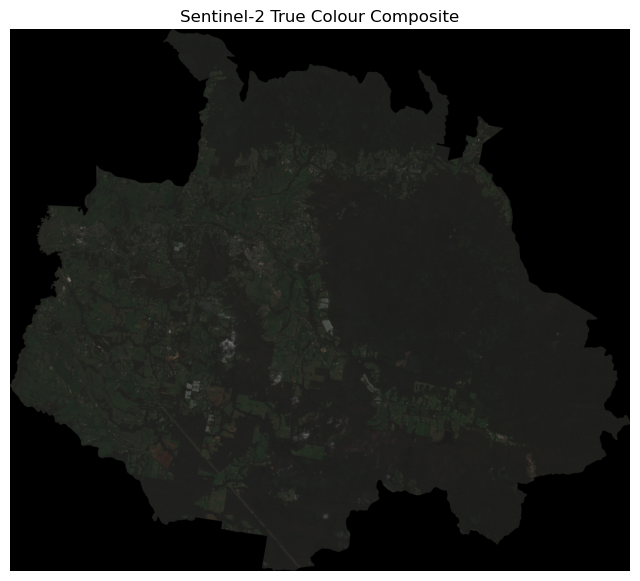

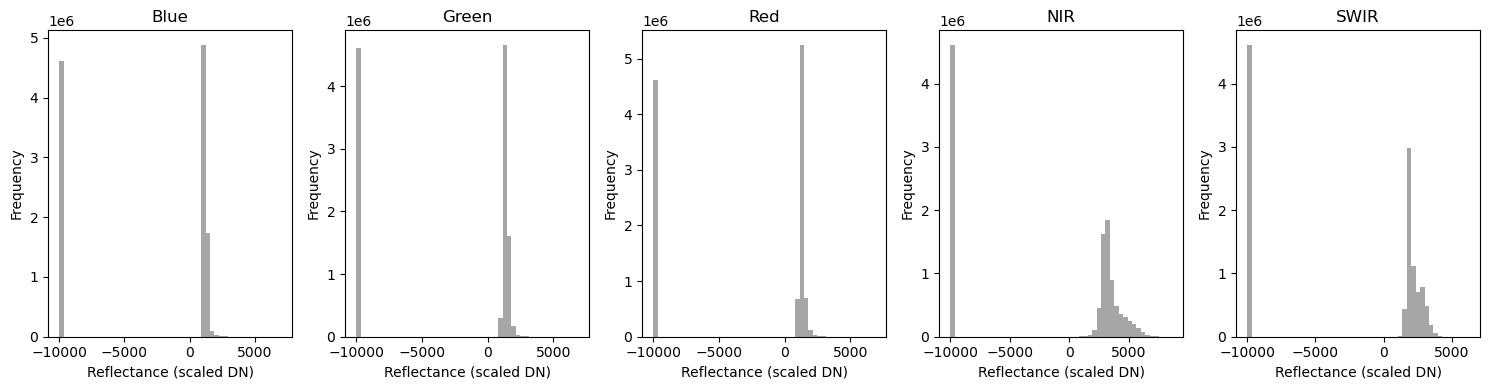

In [29]:
ds_s2 = rasterio.open('data/s2_composite_oct_2022_yarra_ranges_central.tif', 'r')
all_bands = ds_s2.read().astype(np.float32)
nodata = ds_s2.nodata
all_bands[all_bands == nodata] = np.nan

#RGB
rgb = np.stack([all_bands[2], all_bands[1], all_bands[0]], axis=-1)
rgb = np.clip(rgb / 10000, 0, 1)

plt.figure(figsize=(8, 8))
plt.imshow(rgb)
plt.title('Sentinel-2 True Colour Composite', fontsize=12)
plt.axis('off')
plt.show()

# Histograms
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
band_names = ['Blue', 'Green', 'Red', 'NIR', 'SWIR']

for i, ax in enumerate(axes):
    ax.hist(all_bands[i].flatten(), bins=50, color='gray', alpha=0.7)
    ax.set_title(band_names[i])
    ax.set_xlabel('Reflectance (scaled DN)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Question 25

Plot the false colour composite (FCC) with the SWIR band displayed through the red channel, the NIR band through the green channel, and the Blue band through the blue channel. What interpretation can you make with this FCC?

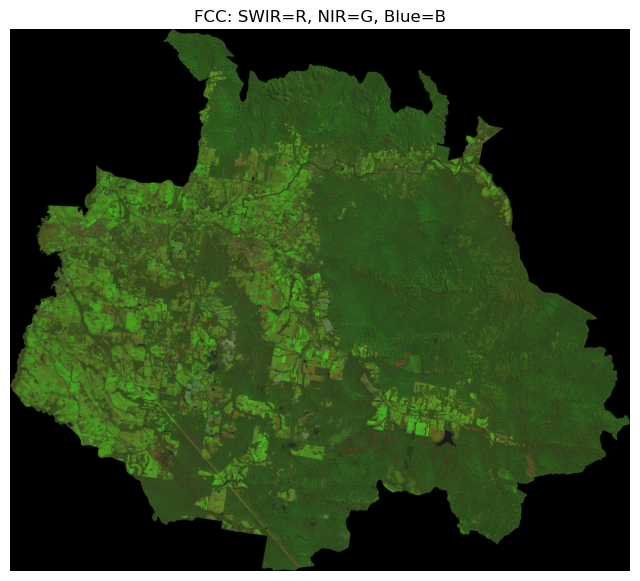

In [8]:
ds = rasterio.open('data/s2_composite_oct_2022_yarra_ranges_central.tif', 'r')

# Read bands
swir = ds.read(5).astype(np.float32) / 10000
nir = ds.read(4).astype(np.float32) / 10000
blue = ds.read(1).astype(np.float32) / 10000

#FCC
fcc = np.stack([swir, nir, blue], axis=-1)
fcc = np.clip(fcc, 0, 1)

plt.figure(figsize=(8, 8))
plt.imshow(fcc)
plt.title('FCC: SWIR=R, NIR=G, Blue=B')
plt.axis('off')
plt.show()

### Question 26

The modified normalised difference water index (MNDWI) can be computed using the equation:

$$MNDWI = \frac{Green - SWIR}{Green + SWIR}$$

Use this index to extract water bodies in the Upper Yarra Valley. What percentage of the DEM's area is occupied by water bodies?

*Hint: Transform the dataset to a projected coordinate system appropriate for the given area.*

In [4]:
import rasterio
import rasterio.warp
from rasterio.enums import Resampling
import numpy as np

with rasterio.open('data/s2_composite_oct_2022_yarra_ranges_central.tif', 'r') as src:
    green = src.read(2).astype(np.float32)
    swir = src.read(5).astype(np.float32)
    nodata = src.nodata
    src_crs = src.crs
    src_transform = src.transform
green[green == nodata] = np.nan
swir[swir == nodata] = np.nan
mndwi = (green - swir) / (green + swir)
water = (mndwi > 0).astype(np.uint8)
dest_crs = rasterio.crs.CRS.from_epsg(7855)

out_transform, out_width, out_height = rasterio.warp.calculate_default_transform(
    src_crs, dest_crs, src.width, src.height, *src.bounds
)

water_reproj = np.empty((out_height, out_width), dtype=np.uint8)
rasterio.warp.reproject(
    source=water,
    destination=water_reproj,
    src_transform=src_transform,
    src_crs=src_crs,
    dst_transform=out_transform,
    dst_crs=dest_crs,
    resampling=Resampling.nearest
)


green_reproj = np.empty((out_height, out_width), dtype=np.float32)
rasterio.warp.reproject(
    source=green,
    destination=green_reproj,
    src_transform=src_transform,
    src_crs=src_crs,
    dst_transform=out_transform,
    dst_crs=dest_crs,
    resampling=Resampling.bilinear
)


valid = ~np.isnan(green_reproj)
water_pct = np.sum(water_reproj[valid]) / np.sum(valid) * 100
print(f"Water bodies occupy approximately {water_pct:.2f}% of the total area")


Water bodies occupy approximately 0.05% of the total area


### Question 27 (Challenge)

Can the water bodies be extracted with NDVI? If yes, how different is the area of NDVI-based extracted water bodies compared to MNDWI? Clearly visualise the differences between the extracted water bodies from MNDWI and NDVI on a single map.

MNDWI water: 0.05%
NDVI water:  0.06%
Difference:  0.01%


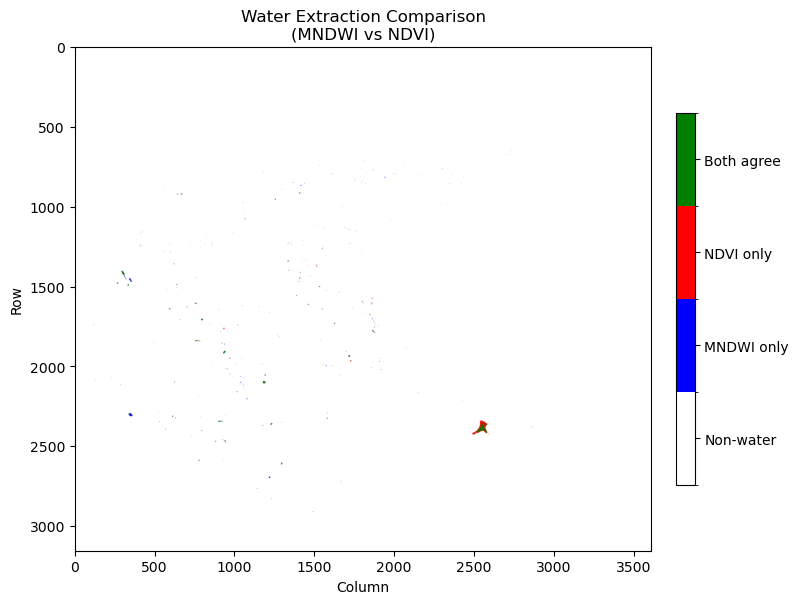

In [33]:
import rasterio
import matplotlib.pyplot as plt
from matplotlib import colors

with rasterio.open('data/s2_composite_oct_2022_yarra_ranges_central.tif', 'r') as src:
    green = src.read(2).astype(np.float32)
    red = src.read(3).astype(np.float32)
    nir = src.read(4).astype(np.float32)
    swir = src.read(5).astype(np.float32)
    nodata = src.nodata

for band in [green, red, nir, swir]:
    band[band == nodata] = np.nan


np.seterr(divide='ignore', invalid='ignore')
ndvi = (nir - red) / (nir + red)
mndwi = (green - swir) / (green + swir)

water_mndwi = mndwi > 0
water_ndvi = ndvi < 0
mndwi_pct = np.nansum(water_mndwi) / np.sum(~np.isnan(mndwi)) * 100
ndvi_pct = np.nansum(water_ndvi) / np.sum(~np.isnan(ndvi)) * 100

print(f"MNDWI water: {mndwi_pct:.2f}%")
print(f"NDVI water:  {ndvi_pct:.2f}%")
print(f"Difference:  {abs(mndwi_pct - ndvi_pct):.2f}%")

diff_map = np.zeros_like(water_mndwi, dtype=np.uint8)
diff_map[water_mndwi & ~water_ndvi] = 1   # 仅 MNDWI
diff_map[~water_mndwi & water_ndvi] = 2   # 仅 NDVI
diff_map[water_mndwi & water_ndvi] = 3    # 两者一致

cmap = colors.ListedColormap(['white', 'blue', 'red', 'green'])
bounds = [0, 1, 2, 3, 4]
norm = colors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(diff_map, cmap=cmap, norm=norm)
ax.set_title('Water Extraction Comparison\n(MNDWI vs NDVI)')
ax.set_xlabel('Column')
ax.set_ylabel('Row')

cbar = plt.colorbar(im, ticks=[0.5, 1.5, 2.5, 3.5], fraction=0.03, pad=0.04)
cbar.ax.set_yticklabels(['Non-water', 'MNDWI only', 'NDVI only', 'Both agree'])
plt.show()